In [1]:
import os
import matplotlib.pyplot as plt
import pandas as pd
import yfinance as yf

# Prevent plots from blocking script execution if run as a single file
plt.ion()

# ==========================================
# 1. Install and import libraries
# ==========================================
# Note: Ensure you have run: pip install pandas yfinance matplotlib
print("--- Step 1: Libraries imported successfully ---")

--- Step 1: Libraries imported successfully ---


In [2]:
# ==========================================
# 2. Retrieve Historical Stock Data
# ==========================================
print("\n--- Step 2: Retrieving Historical Stock Data ---")
ticker = "AAPL"
# Retrieve data for the past 2 years
df = yf.download(ticker, period="2y")

print("\nTop 10 Rows:")
print(df.head(10))
print("\nLast 10 Rows:")
print(df.tail(10))

# Flatten column names if yfinance MultiIndex columns are present
if isinstance(df.columns, pd.MultiIndex):
    df.columns = df.columns.get_level_values(0)


--- Step 2: Retrieving Historical Stock Data ---


/var/folders/hw/mr_tqyws2jx9c63s7wfqf4280000gn/T/ipykernel_80390/2858402919.py:7: FutureWarning: YF.download() has changed argument auto_adjust default to True
  df = yf.download(ticker, period="2y")
[*********************100%***********************]  1 of 1 completed


Top 10 Rows:
Price            Close        High         Low        Open    Volume
Ticker            AAPL        AAPL        AAPL        AAPL      AAPL
Date                                                                
2024-07-08  225.863480  225.893221  221.332720  225.139738  59085900
2024-07-09  226.716080  227.429898  224.425921  225.972521  48076100
2024-07-10  230.979141  231.078288  227.281179  227.330753  62627700
2024-07-11  225.615616  230.394213  223.831071  229.402801  64710600
2024-07-12  228.560104  230.642076  226.716078  226.954022  53046500
2024-07-15  232.386978  235.192676  231.088231  234.449117  62631300
2024-07-16  232.803360  234.240904  230.334739  232.981807  43234300
2024-07-17  226.914368  229.472212  224.693600  227.479465  57345900
2024-07-18  222.254730  228.460979  220.361145  228.302349  66034600
2024-07-19  222.383621  224.852243  221.362468  222.889251  49151500

Last 10 Rows:
Price            Close        High         Low        Open     Volume
Tick

In [3]:
# ==========================================
# 3. Explore, Clean, and Prepare Data
# ==========================================
print("\n--- Step 3: Data Cleaning and Preparation ---")

# b. Parse dates / Ensure DatetimeIndex (yfinance sets Date as index by default)
df.index = pd.to_datetime(df.index)
print(f"Index Type: {type(df.index)}")

# a. Handling Missing Data and Duplicates
print("\nMissing values per column before handling:")
print(df.isnull().sum())

# Demonstrating techniques for handling missing data
df_ffill = df.ffill()
df_bfill = df.bfill()
df_interp = df.interpolate(method="linear")

# Apply cleaning to the primary dataframe
df = df_ffill

# Identify and remove duplicates
duplicates_count = df.index.duplicated().sum()
print(f"Number of duplicate dates: {duplicates_count}")
df = df[~df.index.duplicated(keep="first")]

print("\nCleaned Data Sample:")
print(df.head(3))


--- Step 3: Data Cleaning and Preparation ---
Index Type: <class 'pandas.core.indexes.datetimes.DatetimeIndex'>

Missing values per column before handling:
Price
Close     0
High      0
Low       0
Open      0
Volume    0
dtype: int64
Number of duplicate dates: 0

Cleaned Data Sample:
Price            Close        High         Low        Open    Volume
Date                                                                
2024-07-08  225.863480  225.893221  221.332720  225.139738  59085900
2024-07-09  226.716080  227.429898  224.425921  225.972521  48076100
2024-07-10  230.979141  231.078288  227.281179  227.330753  62627700


In [4]:
# ==========================================
# 4. Formatted Date Variable
# ==========================================
print("\n--- Step 4: Formatted Date ---")
# Convert index dates to 'Month-Day-Year' string format
df_formatted_dates = df.index.strftime("%B-%d-%Y")
print("Sample Formatted Dates (Month-Day-Year):")
print(df_formatted_dates[:5])


--- Step 4: Formatted Date ---
Sample Formatted Dates (Month-Day-Year):
Index(['July-08-2024', 'July-09-2024', 'July-10-2024', 'July-11-2024',
       'July-12-2024'],
      dtype='object', name='Date')


In [5]:
# ==========================================
# 5. Time Series Basics
# ==========================================
print("\n--- Step 5: Time Series Basics ---")
print(f"1. Index Frequency: {df.index.freq}")
print(f"2. First Date: {df.index.min().date()}")
print(f"3. Last Date: {df.index.max().date()}")
print(f"4. Time Period Covered: {df.index.max() - df.index.min()}")


--- Step 5: Time Series Basics ---
1. Index Frequency: None
2. First Date: 2024-07-08
3. Last Date: 2026-07-07
4. Time Period Covered: 729 days 00:00:00


In [6]:
# ==========================================
# 6. Creating Date Ranges and Frequencies
# ==========================================
print("\n--- Step 6: Creating Date Ranges and Frequencies ---")
# Business month end frequency date range covering our data span
business_months = pd.date_range(
    start=df.index.min(), end=df.index.max(), freq="BME"
)
# Filter dataframe to include only these business month-end dates
filtered_df = df[df.index.isin(business_months)]
print("Data filtered to Last Business Day of Each Month:")
print(filtered_df[["Close"]])


--- Step 6: Creating Date Ranges and Frequencies ---
Data filtered to Last Business Day of Each Month:
Price            Close
Date                  
2024-07-31  220.172760
2024-08-30  227.296127
2024-09-30  231.266357
2024-10-31  224.229111
2024-11-29  235.823318
2024-12-31  248.830215
2025-01-31  234.501740
2025-02-28  240.568878
2025-03-31  220.962479
2025-04-30  211.383102
2025-05-30  200.056351
2025-06-30  204.359268
2025-07-31  206.749786
2025-08-29  231.485107
2025-09-30  253.911667
2025-10-31  269.607269
2025-11-28  278.332886
2025-12-31  271.355835
2026-01-30  258.998810
2026-02-27  263.936829
2026-03-31  253.556381
2026-04-30  271.100250
2026-05-29  312.059998
2026-06-30  289.359985


In [7]:
# ==========================================
# 7. Shifting and Rolling Windows
# ==========================================
print("\n--- Step 7: Shifting and Rolling Windows ---")
df_shifts = pd.DataFrame(index=df.index)
df_shifts["Close"] = df["Close"]
df_shifts["Shift_Forward_1D"] = df["Close"].shift(1)
df_shifts["Shift_Backward_1D"] = df["Close"].shift(-1)
df_shifts["Rolling_Mean_7D"] = df["Close"].rolling(window=7).mean()

print("Shifting and 7-day Rolling Mean Sample:")
print(df_shifts.head(10))


--- Step 7: Shifting and Rolling Windows ---
Shifting and 7-day Rolling Mean Sample:
                 Close  Shift_Forward_1D  Shift_Backward_1D  Rolling_Mean_7D
Date                                                                        
2024-07-08  225.863480               NaN         226.716080              NaN
2024-07-09  226.716080        225.863480         230.979141              NaN
2024-07-10  230.979141        226.716080         225.615616              NaN
2024-07-11  225.615616        230.979141         228.560104              NaN
2024-07-12  228.560104        225.615616         232.386978              NaN
2024-07-15  232.386978        228.560104         232.803360              NaN
2024-07-16  232.803360        232.386978         226.914368       228.989251
2024-07-17  226.914368        232.803360         222.254730       229.139378
2024-07-18  222.254730        226.914368         222.383621       228.502042
2024-07-19  222.383621        222.254730         222.036636       2

In [8]:
# ==========================================
# 8. Resampling and Frequency Conversion
# ==========================================
print("\n--- Step 8: Resampling and Frequency Conversion ---")
# Weekly frequency resampling (mean of Close price)
weekly_df = df[["Close"]].resample("W").mean()
print("Weekly Resampled Mean Close Price (Top 5):")
print(weekly_df.head(5))

# Hourly frequency resampling filled with mean values
hourly_df = df[["Close"]].resample("h").asfreq()
hourly_df["Close_Filled_Mean"] = hourly_df["Close"].fillna(df["Close"].mean())
print("\nHouarly Resampled and Mean-Filled (Top 5):")
print(hourly_df.head(5))


--- Step 8: Resampling and Frequency Conversion ---
Weekly Resampled Mean Close Price (Top 5):
Price            Close
Date                  
2024-07-14  227.546884
2024-07-21  227.348611
2024-07-28  218.697549
2024-08-04  217.583209
2024-08-11  209.360428

Houarly Resampled and Mean-Filled (Top 5):
Price                    Close  Close_Filled_Mean
Date                                             
2024-07-08 00:00:00  225.86348         225.863480
2024-07-08 01:00:00        NaN         241.372882
2024-07-08 02:00:00        NaN         241.372882
2024-07-08 03:00:00        NaN         241.372882
2024-07-08 04:00:00        NaN         241.372882



--- Step 9: Moving Windows ---
30-Day Moving Average calculated.


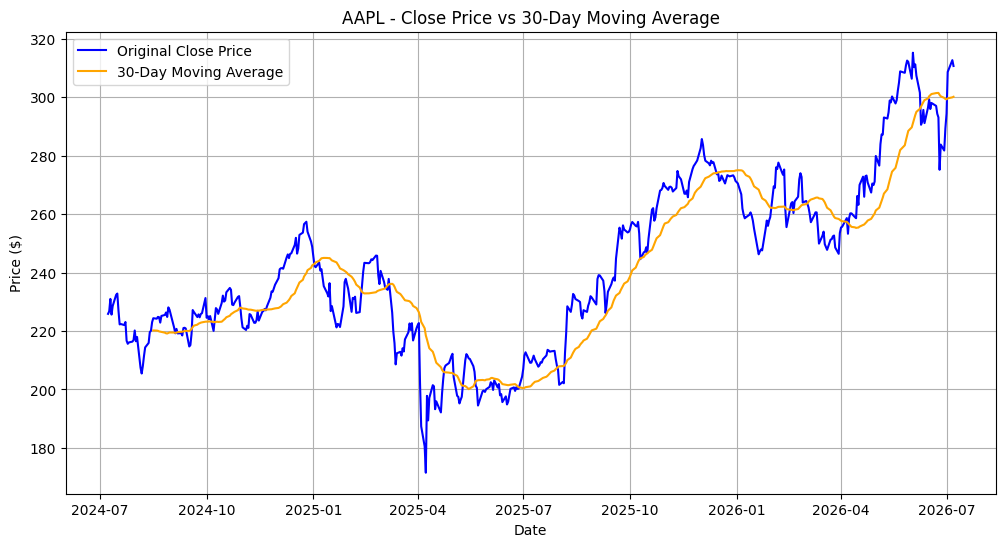

In [9]:
# ==========================================
# 9. Moving Windows
# ==========================================
print("\n--- Step 9: Moving Windows ---")
df["MA_30"] = df["Close"].rolling(window=30).mean()
print("30-Day Moving Average calculated.")

plt.figure(figsize=(12, 6))
plt.plot(df.index, df["Close"], label="Original Close Price", color="blue")
plt.plot(df.index, df["MA_30"], label="30-Day Moving Average", color="orange")
plt.title(f"{ticker} - Close Price vs 30-Day Moving Average")
plt.xlabel("Date")
plt.ylabel("Price ($)")
plt.legend()
plt.grid(True)
plt.show()

In [10]:
# --- Question Answer ---
# The 30-day moving average smooths out high-frequency noise and daily market
# volatility, revealing the underlying medium-term trend. Compared to the raw price
# series, the moving average lags behind rapid price turns because it is a backward-looking metric.


--- Step 10: Percentage Change ---


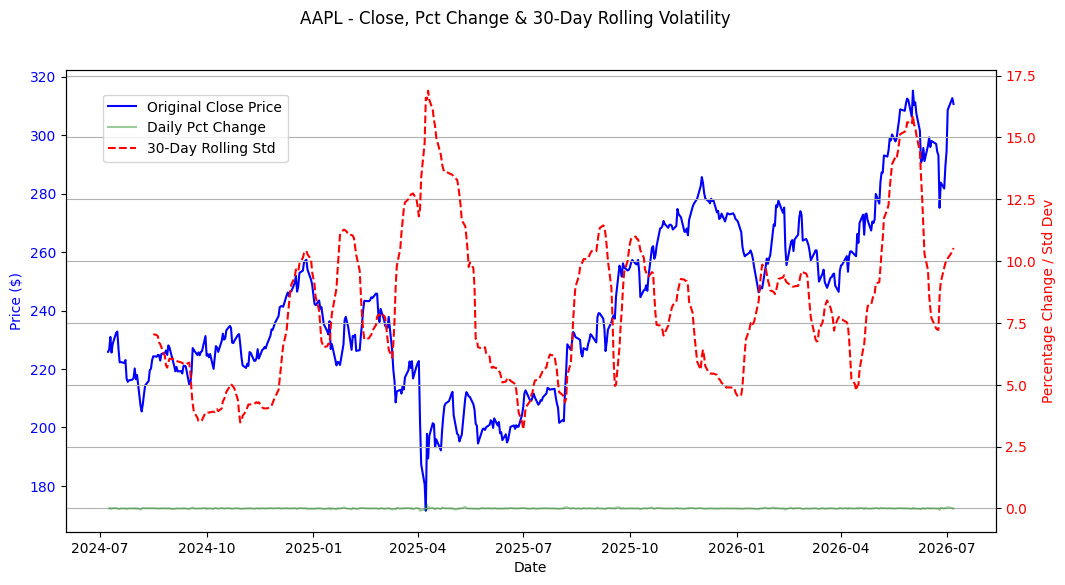

In [11]:
# ==========================================
# 10. Percentage Change
# ==========================================
print("\n--- Step 10: Percentage Change ---")
df["Pct_Change"] = df["Close"].pct_change()
df["Rolling_Std_30"] = df["Close"].rolling(window=30).std()

fig, ax1 = plt.subplots(figsize=(12, 6))
ax1.plot(df.index, df["Close"], label="Original Close Price", color="blue")
ax1.set_xlabel("Date")
ax1.set_ylabel("Price ($)", color="blue")
ax1.tick_params(axis="y", labelcolor="blue")

ax2 = ax1.twinx()
ax2.plot(
    df.index,
    df["Pct_Change"],
    label="Daily Pct Change",
    color="green",
    alpha=0.4,
)
ax2.plot(
    df.index,
    df["Rolling_Std_30"],
    label="30-Day Rolling Std",
    color="red",
    linestyle="--",
)
ax2.set_ylabel("Percentage Change / Std Dev", color="red")
ax2.tick_params(axis="y", labelcolor="red")

fig.suptitle(f"{ticker} - Close, Pct Change & 30-Day Rolling Volatility")
fig.legend(loc="upper left", bbox_to_anchor=(0.15, 0.85))
plt.grid(True)
plt.show()


--- Step 11: Expanding Mean ---


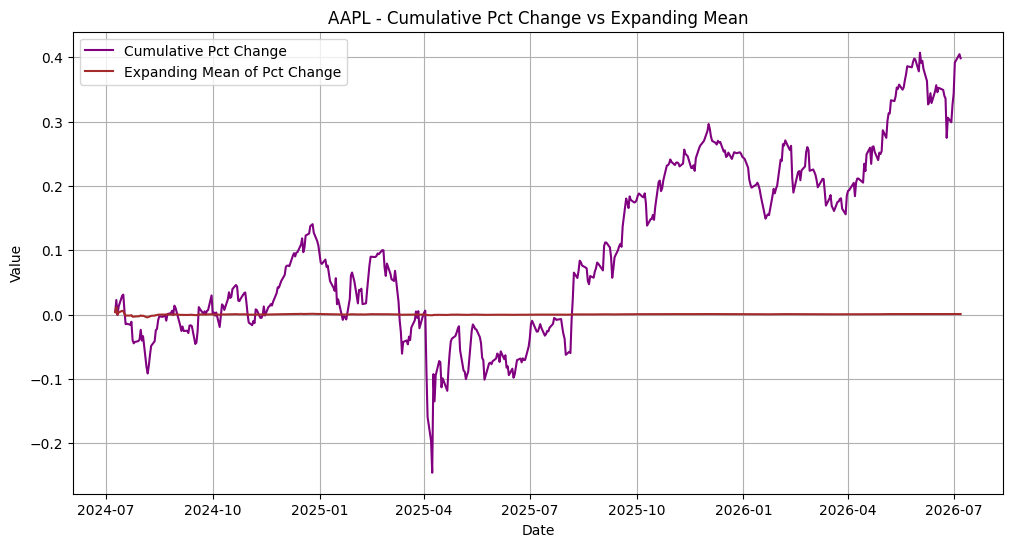

In [12]:
# ==========================================
# 11. Expanding Mean
# ==========================================
print("\n--- Step 11: Expanding Mean ---")
df["Expanding_Mean_Pct"] = df["Pct_Change"].expanding().mean()

plt.figure(figsize=(12, 6))
plt.plot(
    df.index,
    df["Pct_Change"].cumsum(),
    label="Cumulative Pct Change",
    color="purple",
)
plt.plot(
    df.index,
    df["Expanding_Mean_Pct"],
    label="Expanding Mean of Pct Change",
    color="brown",
)
plt.title(f"{ticker} - Cumulative Pct Change vs Expanding Mean")
plt.xlabel("Date")
plt.ylabel("Value")
plt.legend()
plt.grid(True)
plt.show()

In [13]:
# --- Question Answer ---
# The cumulative percentage change scales up over time as returns stack, charting the overall
# asset trajectory. The expanding mean shows the long-term stable average daily return, which
# progressively dampens and converges toward a steady baseline as time goes on.


--- Step 12: Exponentially Weighted Moving Average ---


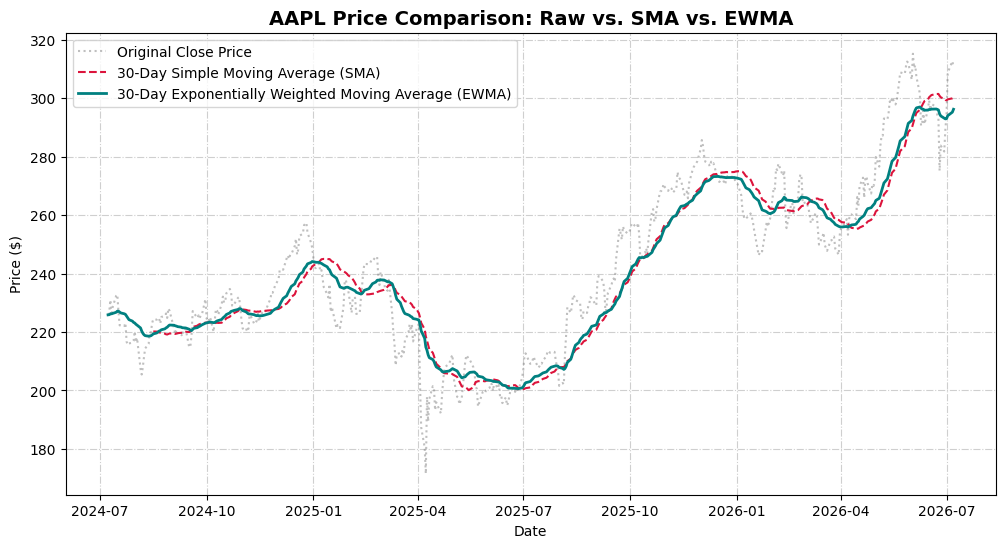

In [14]:
# ==========================================
# 12. Exponentially Weighted Moving Average
# ==========================================
print("\n--- Step 12: Exponentially Weighted Moving Average ---")
df["EWMA_30"] = df["Close"].ewm(span=30, adjust=False).mean()

plt.figure(figsize=(12, 6))
plt.plot(
    df.index,
    df["Close"],
    label="Original Close Price",
    color="gray",
    alpha=0.5,
    linestyle=":",
)
plt.plot(
    df.index,
    df["MA_30"],
    label="30-Day Simple Moving Average (SMA)",
    color="crimson",
    linestyle="--",
)
plt.plot(
    df.index,
    df["EWMA_30"],
    label="30-Day Exponentially Weighted Moving Average (EWMA)",
    color="teal",
    linewidth=2,
)

plt.title(
    f"{ticker} Price Comparison: Raw vs. SMA vs. EWMA",
    fontsize=14,
    fontweight="bold",
)
plt.xlabel("Date")
plt.ylabel("Price ($)")
plt.legend(loc="best")
plt.grid(True, linestyle="-.", alpha=0.6)
plt.show(block=True)  # Blocks process at final window closure

# --- Question Answer ---
# The EWMA smooths out short-term fluctuations but places heavier mathematical weight on recent prices.
# Consequently, it reacts and responds much faster to price reversals than the standard 30-day Simple
# Moving Average, keeping it closer to the raw price line while still filtering out minor noise.